In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# High-frequency dynamics (monthly and quarterly Eurostat series, 2005-2026)
The annual panel cannot answer timing questions. Here: 12 monthly and 4 quarterly series (unemployment, HICP, industrial production, retail, 10-year yields, sentiment, GDP growth, employment, hours, labour cost), 31 countries and aggregates.
Safeguards: every series is **transformed to be approximately stationary** before any comparison (levels of yields, indices and prices trend and would correlate by accident); cross-correlations are **prewhitened**; panel tests control for the dependent series' own past with **country and month effects and country-clustered errors**; events are judged against a **placebo distribution from every other month of the same series** and corrected for multiple testing (BH-FDR).
**Predictive order and association only, never causal.** Code: `src/cifresignificative/analysis/hf.py`, `experiments.py`.

In [2]:
from cifresignificative.analysis import hf as H, experiments as ex
hf = H.load_highfreq()
res = ex.run_hf_all(hf)
display(hf.groupby("indicator").agg(countries=("iso3", "nunique"), observations=("value", "size"), first=("period", "min"), last=("period", "max")))
display(res["hf0_stationarity"].round(2))

,countries,observations,first,last
indicator,,,,
m_consumer_confidence,28,7297,2005-01,2026-09
m_esi,28,7257,2005-01,2026-09
m_hicp_core_inflation,29,7445,2005-01,2026-09
m_hicp_energy_inflation,29,7445,2005-01,2026-09
m_hicp_inflation,30,7732,2005-01,2026-09
m_industrial_production,28,7278,2005-01,2026-08
m_industry_confidence,28,7257,2005-01,2026-09
m_long_term_yield,29,7352,2005-01,2026-09
m_retail_volume,28,6872,2005-01,2026-08


,indicator,transform,countries,share_stationary,median_adf_p,median_kpss_p
0,m_consumer_confidence,diff,28,1.00,0.00,0.1
1,m_consumer_confidence,level,28,0.11,0.16,0.1
2,m_esi,diff,28,1.00,0.00,0.1
3,m_esi,level,28,0.68,0.01,0.1
4,m_hicp_core_inflation,diff,29,1.00,0.00,0.1
5,m_hicp_energy_inflation,diff,29,1.00,0.00,0.1
6,m_hicp_inflation,diff,30,1.00,0.00,0.1
7,m_hicp_inflation,level,30,0.10,0.11,0.1
8,m_industrial_production,dlog,28,0.96,0.00,0.1
9,m_industry_confidence,level,28,0.71,0.01,0.1


## H1 - the Italy-Germany spread
The spread (10-year yield, Italy minus Germany) with Italian government changes and ECB decisions. Then the monthly change in the spread regressed on the previous month's (standardised) differentials with Germany: sentiment, change in unemployment, change in core inflation, industrial growth; Newey-West errors, by regime.

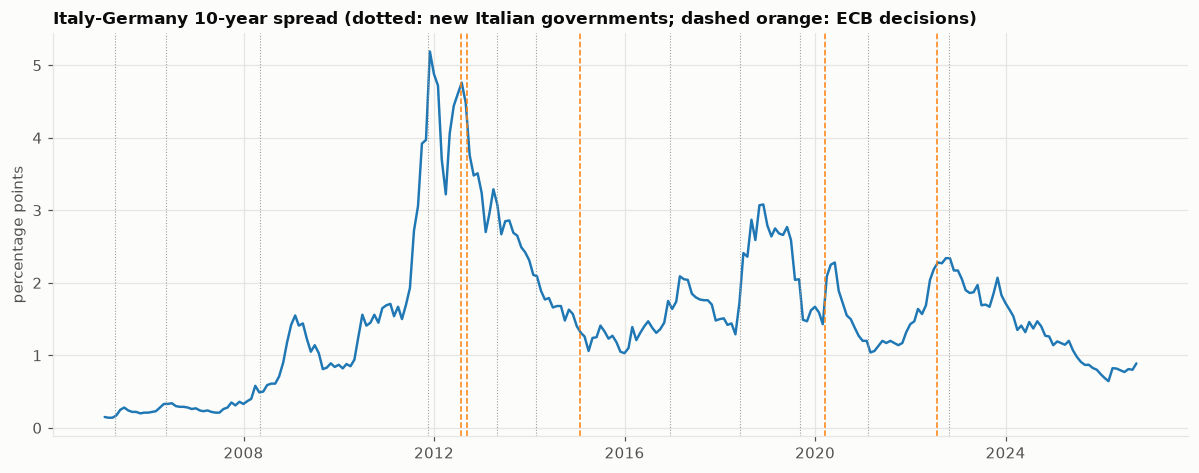

peak: 2011-11-30 5.19 pp; latest: 2026-09-30 0.89 pp


,regime,regressor,coef_pp_per_sd,se,p,q_value,n,r2
0,full sample,sentiment_gap,0.006,0.017,0.705,0.920,258,0.013
1,full sample,unemployment_change_gap,0.005,0.012,0.674,0.920,258,0.013
2,full sample,core_inflation_change_gap,0.005,0.012,0.654,0.918,258,0.013
3,full sample,industrial_growth_gap,-0.025,0.010,0.017,0.273,258,0.013
4,2005-2011,sentiment_gap,-0.081,0.046,0.078,0.538,82,0.157
5,2005-2011,unemployment_change_gap,-0.019,0.031,0.534,0.899,82,0.157
6,2005-2011,core_inflation_change_gap,0.016,0.017,0.347,0.794,82,0.157
7,2005-2011,industrial_growth_gap,-0.025,0.021,0.229,0.717,82,0.157
8,2012-2019,sentiment_gap,0.044,0.024,0.067,0.538,96,0.045
9,2012-2019,unemployment_change_gap,0.033,0.024,0.161,0.644,96,0.045


Other countries, share of coefficients with q < 0.05 by country:


country,ESP,FRA,GRC,ITA,PRT
share,0.0,0.0,0.0,0.0,0.06


In [3]:
sp = H.spread_series(hf)
ev = ex.italian_events()
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(sp.index, sp.values, color="C0", lw=1.6)
for d in ev[ev.type == "government"].date: ax.axvline(d, color="0.6", lw=0.7, ls=":")
for d, t in zip(ev[ev.type == "ecb"].date, ev[ev.type == "ecb"].event): ax.axvline(d, color="C1", lw=1, ls="--")
ax.set_ylabel("percentage points"); ax.set_title("Italy-Germany 10-year spread (dotted: new Italian governments; dashed orange: ECB decisions)")
plt.tight_layout(); plt.show()
print("peak:", sp.idxmax().date(), round(sp.max(), 2), "pp; latest:", sp.dropna().index[-1].date(), round(sp.dropna().iloc[-1], 2), "pp")
s = res["hf1_spread"]
display(s[s.country == "ITA"][["regime", "regressor", "coef_pp_per_sd", "se", "p", "q_value", "n", "r2"]].round(3))
print("Other countries, share of coefficients with q < 0.05 by country:"); display(s.groupby("country").apply(lambda g: (g.q_value < 0.05).mean()).round(2).to_frame("share").T)

## H2 - business-cycle lead-lag
Panel Granger tests (country + month effects, own lags controlled, country-clustered errors), both directions, at 1, 3, 6 and 12 months (quarters for GDP). `x leads` / `y leads` = only that direction is significant at 5%.

In [4]:
p = res["hf2_panel"]
display(p.pivot_table(index=["x", "y"], columns="lag", values="verdict", aggfunc="first"))
print("Italy against the other countries (prewhitened cross-correlation, lag 0-12 with the largest |r|; rank 1 = strongest):")
display(res["hf2_italy"].round(3))

lag                                                   1        2        3   \
x                       y                                                    
m_consumer_confidence   m_retail_volume          neither      NaN  y leads   
m_esi                   m_industrial_production     both      NaN  neither   
                        m_unemployment_rate         both      NaN     both   
m_industrial_production m_unemployment_rate      neither      NaN  neither   
m_industry_confidence   m_industrial_production     both      NaN  y leads   
m_services_confidence   m_unemployment_rate         both      NaN     both   
q_gdp_growth            q_employment_ths         x leads     both      NaN   
                        q_hours_ths              x leads  x leads      NaN   

lag                                                4        6        12  
x                       y                                                
m_consumer_confidence   m_retail_volume           NaN  y leads  neither  
m_esi                   m_industrial_production   NaN  neither  neither  
                        m_unemployment_rate       NaN     both     both  
m_industrial_production m_unemployment_rate       NaN  x leads  neither  
m_industry_confidence   m_industrial_production   NaN  neither  neither  
m_services_confidence   m_unemployment_rate       NaN     both     both  
q_gdp_growth            q_employment_ths         both      NaN      NaN  
                        q_hours_ths              both      NaN      NaN

Italy against the other countries (prewhitened cross-correlation, lag 0-12 with the largest |r|; rank 1 = strongest):


,x,y,italy_lag,italy_r,rank_by_abs_r,n_countries,median_lag_all,share_significant
0,m_consumer_confidence,m_retail_volume,0,0.302,7,26,0.0,0.885
1,m_esi,m_industrial_production,0,-0.263,10,27,1.0,0.889
2,m_esi,m_unemployment_rate,1,-0.153,13,27,2.0,0.778
3,m_industrial_production,m_unemployment_rate,0,0.358,2,27,2.0,0.963
4,m_industry_confidence,m_industrial_production,0,-0.318,6,27,1.0,0.778
5,m_services_confidence,m_unemployment_rate,0,-0.211,6,26,2.0,0.731


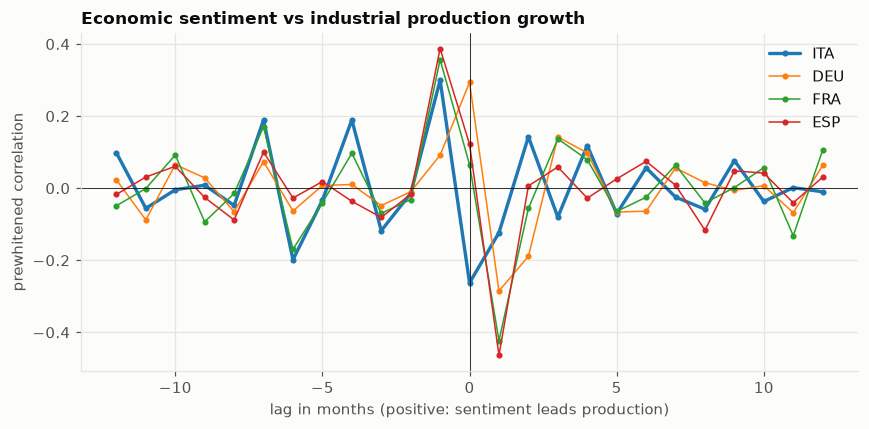

In [5]:
X, Y = H.transformed(hf, "m_esi"), H.transformed(hf, "m_industrial_production")
cc = {c: H.cross_corr(X[c], Y[c], 12) for c in ["ITA", "DEU", "FRA", "ESP"]}
fig, ax = plt.subplots(figsize=(8, 4))
for c, d in cc.items(): ax.plot(d.lag, d.r, marker="o", ms=3, label=c, lw=2.2 if c == "ITA" else 1)
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5); ax.set_xlabel("lag in months (positive: sentiment leads production)")
ax.set_ylabel("prewhitened correlation"); ax.set_title("Economic sentiment vs industrial production growth"); ax.legend(); plt.tight_layout(); plt.show()

## H3 - from inflation to wages
Hourly labour cost growth on average inflation over the current and previous four quarters, controlling for unemployment; country and quarter effects. The coefficient is the cumulative pass-through (pp of wage growth per pp of inflation).

In [6]:
display(res["hf3_passthrough_panel"].round(3))
print("Italy against the other countries (country-by-country regression, 2005Q1-2021Q2):"); display(res["hf3_passthrough_italy"].round(3))
c = res["hf3_passthrough_countries"]; display(c.sort_values("pass_through", ascending=False).head(8).round(3))

,window,pass_through,p,unemployment_coef,n_obs,n_countries
0,2005Q1-2021Q2,0.437,0.039,-0.479,1651,28
1,2021Q3-2023Q4 (energy shock),0.025,0.767,-1.185,270,27


Italy against the other countries (country-by-country regression, 2005Q1-2021Q2):


,window,italy_value,rank,n_countries,median_all
0,2005Q1-2021Q2,0.315,19,27,0.427


,iso3,pass_through,se,p,n,window
8,EST,0.970,0.295,0.001,62,2005Q1-2021Q2
19,LVA,0.960,0.335,0.004,62,2005Q1-2021Q2
2,BGR,0.834,0.311,0.007,62,2005Q1-2021Q2
1,BEL,0.708,0.183,0.000,62,2005Q1-2021Q2
14,HUN,0.706,0.130,0.000,62,2005Q1-2021Q2
23,ROU,0.671,0.433,0.122,62,2005Q1-2021Q2
20,NLD,0.618,0.174,0.000,62,2005Q1-2021Q2
9,FIN,0.545,0.294,0.064,62,2005Q1-2021Q2


## H4 - events
Change in each series in the six months after a dated event minus the six months before, against a placebo distribution from all other months. 57 events (Italian governments, Italian policies, ECB decisions) x 4 series; q-values correct for the whole family. Events cluster at crisis turning points, and several policies share a month (identical rows), so read the table as a screen.

In [7]:
e = res["hf4_events"]
print("tests:", len(e), " | p < 0.05:", int((e.p < 0.05).sum()), " | q < 0.10:", int((e.q_value < 0.10).sum()), " | q < 0.05:", int((e.q_value < 0.05).sum()))
display(e.head(12)[["label", "event", "type", "date", "change", "z", "p", "q_value"]].round(3))
print("share with p < 0.05 by event type:"); display(e.groupby("type").apply(lambda g: (g.p < 0.05).mean()).round(2).to_frame("share").T)

tests: 218  | p < 0.05: 16  | q < 0.10: 0  | q < 0.05: 0


,label,event,type,date,change,z,p,q_value
0,Italy 10y yield (%),First rate rise since 2011 (+50 bp) and Transm...,ecb,2022-07-21,1.775,3.115,0.004,0.121
1,Italy 10y yield (%),Universal single child allowance (assegno unic...,policy,2022-03-01,2.155,3.841,0.004,0.121
2,Italy unemployment rate (%),Salva Italia decree (Monti): Fornero pension r...,policy,2011-12-06,1.633,3.393,0.004,0.121
3,Italy unemployment rate (%),Constitutional balanced-budget amendment,policy,2012-04-20,1.400,2.909,0.004,0.121
4,Italy unemployment rate (%),Monti,government,2011-11-16,1.600,3.297,0.004,0.121
5,Italy economic sentiment,Draghi,government,2021-02-13,22.600,3.355,0.004,0.121
6,Italy economic sentiment,Recovery and Resilience Plan (PNRR) submitted ...,policy,2021-04-30,23.700,3.501,0.004,0.121
7,Italy economic sentiment,Delegation law for the universal child allowance,policy,2021-04-01,23.700,3.501,0.004,0.121
8,Italy-Germany 10y spread (pp),Monti,government,2011-11-16,1.287,2.864,0.013,0.307
9,Italy unemployment rate (%),Fornero labour market reform,policy,2012-06-28,1.183,2.422,0.021,0.462


share with p < 0.05 by event type:


type,ecb,government,policy
share,0.11,0.1,0.06


## Takeaways (Eurostat monthly and quarterly series, 2005-2026; predictive order and association only)
- **Data.** 16 series (12 monthly, 4 quarterly) for 23-31 countries and aggregates, 2005 to September 2026. HICP comes from the ECOICOP-2 dataset (`prc_hicp_minr`) because the old `prc_hicp_manr` stops in December 2025. Levels are mostly non-stationary (only 10% of countries pass ADF+KPSS for the inflation rate and 21% for labour-cost growth), while the transformed series pass in 68-100% of countries (sentiment levels are the weakest, 68-78%), so all tests use changes or growth rates.
- **The Italy-Germany spread** peaked at 5.19 pp in November 2011 (Monti's government took office that month) and stood at 0.89 pp in September 2026. The monthly change in the spread is hardly explained by the previous month's differentials with Germany (R2 1-16% by regime): nothing survives false-discovery control; the nominal best, industrial-growth gap (-0.025 pp per SD, q = 0.27 over the full sample and q = 0.16 since 2020), is small and does not hold across regimes. The same holds for Spain, France, Portugal and Greece (one coefficient in 80 has q < 0.05).
- **Business-cycle lead-lag (panel Granger tests, 27 countries).** Sentiment and industry confidence help predict industrial production growth one month ahead (and production predicts sentiment: both directions); at 3 months only industry confidence's *reverse* direction remains. Consumer confidence does not lead retail sales; retail sales lead consumer confidence at 3-6 months. Industrial production leads the change in unemployment only at 6 months, and sentiment and services confidence relate to unemployment in both directions at every lag. GDP growth leads employment and hours growth by 1-2 quarters (employment also predicts GDP at 2-4 quarters).
- **Italy's timing.** For Italy, the strongest prewhitened relation between industrial production growth and the change in unemployment is positive at lag 0 (r = 0.36, 2nd of 27 countries) because of 2020, when measured Italian unemployment fell in the lockdown months while output collapsed. Excluding March 2020 to June 2021 it becomes r = -0.07 at lag 0 and the strongest relation is a lead of production over unemployment of 6 months (r = -0.16), the same lead as the panel. Italy ranks 6th-13th of 26-27 on the sentiment and confidence relations, so nothing singles it out.
- **Wage pass-through.** Over 2005Q1-2021Q2 a one-point rise in average inflation (current and four previous quarters) goes with +0.44 pp of hourly labour-cost growth (p = 0.04, 28 countries); Italy's own estimate is 0.32, 19th of 27 (median 0.43). In 2021Q3-2023Q4, with quarter effects absorbing the common shock, the coefficient is 0.03 (p = 0.77): no detectable differential pass-through across countries in the energy-shock window.
- **Events (57 dated events x 4 series = 218 tests).** 16 have p < 0.05 (7%, close to the 5% expected by chance) and none has q < 0.10. The largest moves coincide with crisis turning points (Monti and the Salva Italia decree with unemployment +1.6 pp and the spread +1.3 pp over the following six months; the Draghi government and PNRR with sentiment +23 points, a post-pandemic rebound; the July 2022 ECB hike and TPI with the 10-year yield +1.8 pp), so the event dates cannot be separated from the cycle. No event type stands out (6-11% with p < 0.05 for policy, government and ECB events).
- **Limits:** associations and predictive order only; events are few, cluster in time and several share a month; HAC and country-clustered errors with 27 countries; seasonal adjustment by Eurostat; HICP from a reclassified dataset; GBR/USA/JPN are mostly absent from the monthly yield series.